# 01 · Exploratory data analysis

**Goal.** Before writing any scoring logic, understand (1) how trustworthy the data is, (2) what "good" and "bad" outcomes look like, and (3) which signals actually separate accounts that churn from accounts that expand. The last section turns the findings into concrete design decisions for `src/scoring.py`.

**Dataset.** `data/raw/account_data.csv`, 1,000 synthetic accounts, 16 columns. The brief says to treat it like a production dataset, so the first thing we do is try to break it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", palette="muted")

RAW = "../data/raw/account_data.csv"

## 1. Loading the file (and the first trap)

Read it the way most people would, with pandas defaults.

In [2]:
naive = pd.read_csv(RAW)
print("Shape:", naive.shape)
print("\nMissing values with default parsing:")
print(naive.isna().sum()[lambda s: s > 0].to_string())
print("\nRegion values with default parsing:")
print(naive["region"].value_counts(dropna=False).to_string())

Shape: (1000, 16)

Missing values with default parsing:
region                            402
days_since_last_sales_activity     20
ai_usage                           30
call_transcript_summary            52

Region values with default parsing:
region
NaN      402
EMEA     254
APAC     193
LATAM    151


`region` shows **402 missing values and no `NA` category**, although the brief lists NA (North America) as one of the four regions. pandas treats the literal string `"NA"` as a missing-value marker by default, so 40% of the accounts silently lose their region.

Fix: disable the default NA list and only treat empty strings as missing. The two numeric columns that have genuine blanks are coerced explicitly.

In [3]:
df = pd.read_csv(RAW, keep_default_na=False, na_values=[""])
for col in ["days_since_last_sales_activity", "ai_usage"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Region values after the fix:")
print(df["region"].value_counts().to_string())
print("\nGenuine missing values:")
print(df.isna().sum()[lambda s: s > 0].to_string())

Region values after the fix:
region
NA       402
EMEA     254
APAC     193
LATAM    151

Genuine missing values:
days_since_last_sales_activity    20
ai_usage                          30
call_transcript_summary           52


Three columns have real gaps: `call_transcript_summary` (52), `ai_usage` (30) and `days_since_last_sales_activity` (20). We check later whether missingness itself carries signal.

## 2. Schema and shape

In [4]:
df.head(3).T

,0,1,2
account_id,ACC-0001,ACC-0002,ACC-0003
account_name,Bolt Tech Ventures,Jade Campus AI,Wave Alloy Dynamics
account_description,Builds developer productivity platforms with integrated CI/CD pipelines.,Builds virtual classroom tools with real-time collaboration features.,Manufactures steel structural components for commercial construction projects.
industry,Technology,Education,Manufacturing
segment,SMB,SMB,SMB
region,APAC,LATAM,NA
nr_employees,53,174,196
days_to_next_renewal,33,143,183
days_since_last_sales_activity,58.0,139.0,49.0
nr_support_tickets,0,11,3


In [5]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
nr_employees,1000.0,6145.63,12429.09,10.00,123.75,733.50,1855.00,49974.00
days_to_next_renewal,1000.0,148.72,69.40,30.00,92.00,150.00,208.00,270.00
days_since_last_sales_activity,980.0,63.78,36.89,0.00,38.00,62.00,88.00,180.00
nr_support_tickets,1000.0,4.20,3.09,0.00,2.00,4.00,6.00,15.00
ai_usage,970.0,0.33,0.25,0.00,0.09,0.32,0.51,1.00
nr_active_users,1000.0,166.01,307.85,1.00,16.00,37.00,105.00,1796.00
nr_licensed_seats,1000.0,276.58,483.40,5.00,31.00,69.00,173.00,1997.00
current_revenue,1000.0,246500.57,474933.14,2057.74,13333.61,41937.79,90462.99,1991499.74
revenue_end_of_quarter,1000.0,254899.47,524728.17,0.00,10514.55,33954.16,93012.78,2631825.33


Observations:

- Everything is heavily right-skewed: `nr_employees` runs from 10 to ~50k, `current_revenue` from $2k to $2M. Any scoring that uses raw revenue needs a log transform or it becomes an "Enterprise only" list.
- `days_to_next_renewal` is uniform-ish between 30 and 270 days: nobody is renewing *this week*, so "urgency" is relative, not absolute.
- `ai_usage` is within [0, 1] as documented. `nr_active_users` never exceeds `nr_licensed_seats`.
- `revenue_end_of_quarter` has a minimum of 0: some accounts fully churned by quarter end.

## 3. Data quality checks

In [6]:
checks = {
    "duplicate account_id": df["account_id"].duplicated().sum(),
    "duplicate account_name": df["account_name"].duplicated().sum(),
    "ai_usage outside [0, 1]": ((df["ai_usage"] < 0) | (df["ai_usage"] > 1)).sum(),
    "active_users > licensed_seats": (df["nr_active_users"] > df["nr_licensed_seats"]).sum(),
    "licensed_seats > nr_employees": (df["nr_licensed_seats"] > df["nr_employees"]).sum(),
    "any negative numeric value": (df.select_dtypes("number") < 0).any(axis=1).sum(),
    "current_revenue == 0": (df["current_revenue"] == 0).sum(),
    "revenue_end_of_quarter == 0": (df["revenue_end_of_quarter"] == 0).sum(),
    "missing call transcript": df["call_transcript_summary"].isna().sum(),
}
pd.Series(checks, name="count").to_frame()

,count
duplicate account_id,0
duplicate account_name,0
"ai_usage outside [0, 1]",0
active_users > licensed_seats,0
licensed_seats > nr_employees,33
any negative numeric value,0
current_revenue == 0,0
revenue_end_of_quarter == 0,82
missing call transcript,52


In [7]:
odd = df[df["nr_licensed_seats"] > df["nr_employees"]]
print(f"{len(odd)} accounts hold more licensed seats than they have employees. All of them:")
print(odd["segment"].value_counts().to_string())
odd[["account_id", "account_name", "segment", "nr_employees", "nr_licensed_seats", "nr_active_users"]].head(8)

33 accounts hold more licensed seats than they have employees. All of them:
segment
SMB    33


,account_id,account_name,segment,nr_employees,nr_licensed_seats,nr_active_users
5,ACC-0006,Vertex Media Global,SMB,15,30,22
28,ACC-0029,Alpha Store Platform,SMB,26,44,31
40,ACC-0041,Prism Cure Ventures,SMB,35,49,37
42,ACC-0043,Luma Craft Analytics,SMB,12,22,10
113,ACC-0114,Vivid Store Ventures,SMB,13,15,9
126,ACC-0127,Wave Logic Group,SMB,26,30,21
129,ACC-0130,Xenon Mold Studio,SMB,13,25,20
165,ACC-0166,Bolt Campus Works,SMB,11,18,5


No duplicates, no out-of-range values, no negative numbers. The one anomaly is **33 SMB accounts with more licensed seats than employees** (e.g. 15 employees, 38 seats). Plausible explanations: contractors, a stale headcount, or seats sold to a parent company. Not worth dropping; worth a flag, because `nr_employees` is unreliable for these accounts and seat-expansion logic ("room to grow = employees − seats") would go negative.

Does the `segment` label agree with company size?

               min      25%      50%      75%      max
segment                                               
SMB           10.0     54.0     98.0    147.0   2925.0
Mid-Market   207.0    643.0   1164.0   1542.0   1997.0
Enterprise  2115.0  14970.0  26919.0  38963.0  49974.0


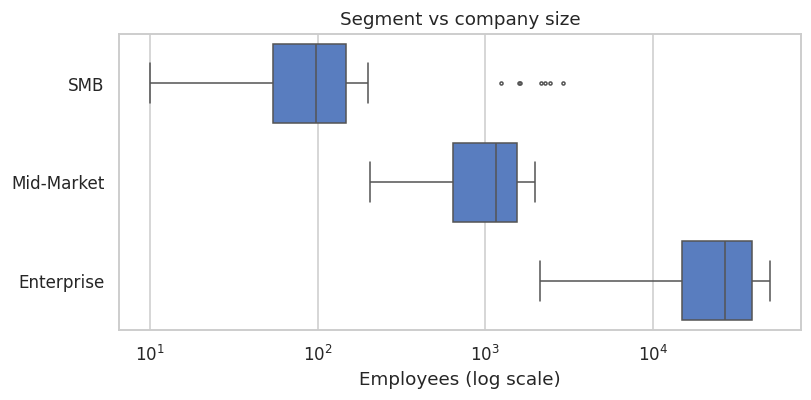

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
order = ["SMB", "Mid-Market", "Enterprise"]
sns.boxplot(data=df, x="nr_employees", y="segment", order=order, ax=ax, fliersize=2)
ax.set_xscale("log")
ax.set_xlabel("Employees (log scale)")
ax.set_ylabel("")
ax.set_title("Segment vs company size")
plt.show()

print(df.groupby("segment")["nr_employees"].describe()[["min", "25%", "50%", "75%", "max"]].round(0).reindex(order).to_string())

Segments are clean and almost non-overlapping (SMB < ~200, Mid-Market 200–2,000, Enterprise > 2,000), with four SMB accounts above 2,000 employees as the only exceptions. `segment` can safely be used as the peer group for benchmarking an account against "companies like it".

## 4. Distributions

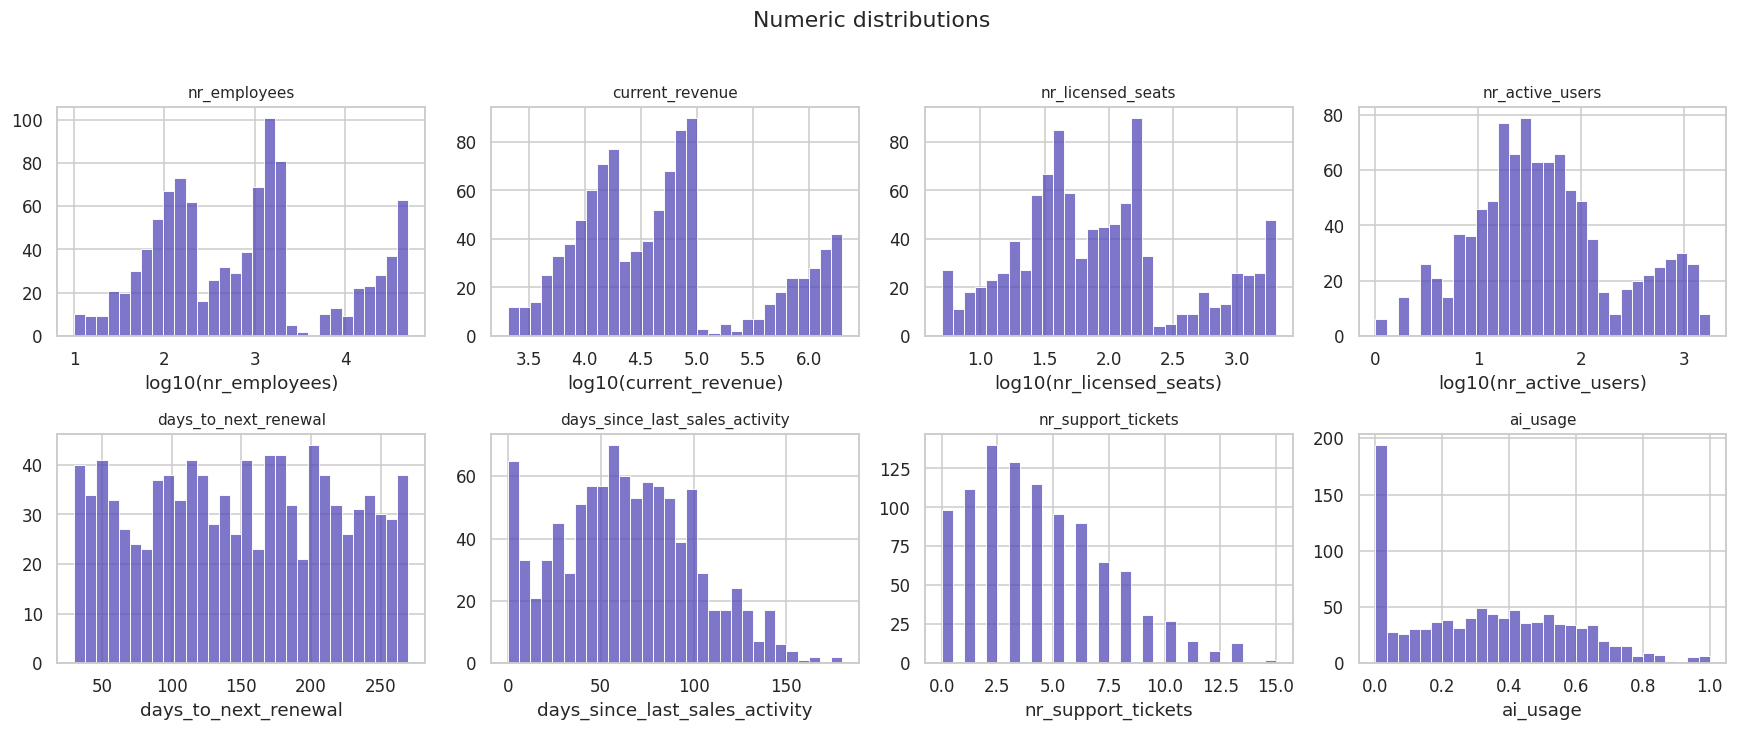

In [9]:
num_cols = [
    "nr_employees", "current_revenue", "nr_licensed_seats", "nr_active_users",
    "days_to_next_renewal", "days_since_last_sales_activity", "nr_support_tickets", "ai_usage",
]
log_cols = {"nr_employees", "current_revenue", "nr_licensed_seats", "nr_active_users"}

fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, col in zip(axes.ravel(), num_cols):
    data = df[col].dropna()
    if col in log_cols:
        sns.histplot(np.log10(data), bins=30, ax=ax, color="#534AB7")
        ax.set_xlabel(f"log10({col})")
    else:
        sns.histplot(data, bins=30, ax=ax, color="#534AB7")
    ax.set_ylabel("")
    ax.set_title(col, fontsize=10)
fig.suptitle("Numeric distributions", y=1.02)
plt.tight_layout()
plt.show()

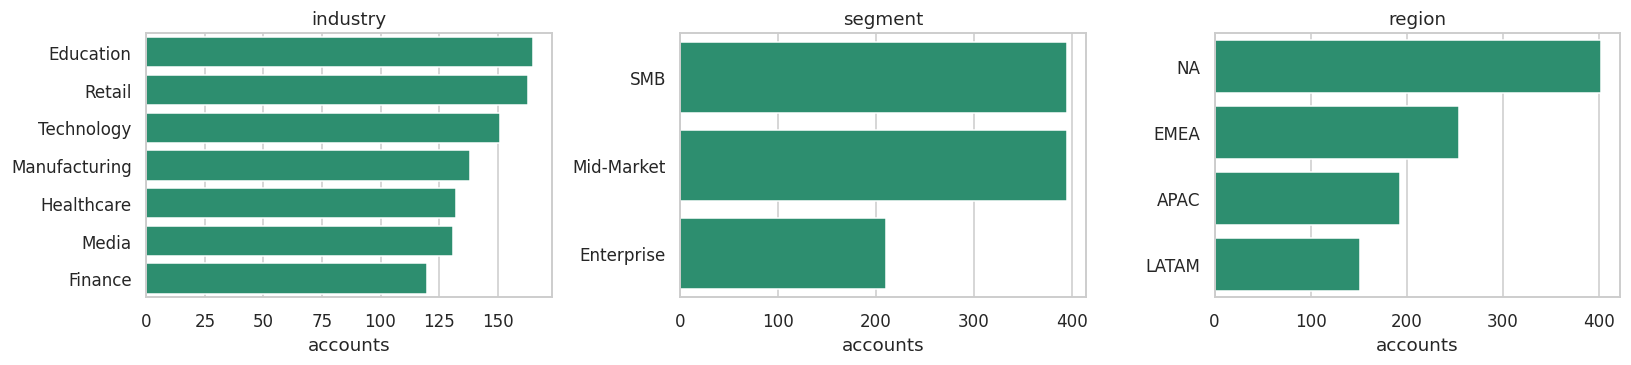

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, ["industry", "segment", "region"]):
    vc = df[col].value_counts()
    sns.barplot(x=vc.values, y=vc.index, ax=ax, color="#1D9E75")
    ax.set_title(col)
    ax.set_xlabel("accounts")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

Industries are balanced (120–165 each), segments are 40/40/20, and NA is the largest region at 40% — which is exactly the slice that disappears with naive parsing.

## 5. Defining the outcome from `revenue_end_of_quarter`

This column is **the future**: actual revenue at the end of the quarter. Using it as a feature would be label leakage: the app is meant to help an AE *before* the quarter ends. But it is a gift as **ground truth**: it lets us check whether a prioritisation heuristic ranks the accounts that really churned or expanded near the top.

We derive a four-class outcome:

In [11]:
df["revenue_delta"] = df["revenue_end_of_quarter"] - df["current_revenue"]
df["revenue_ratio"] = df["revenue_end_of_quarter"] / df["current_revenue"]
df["outcome"] = np.select(
    [df["revenue_end_of_quarter"] == 0, df["revenue_delta"] < 0, df["revenue_delta"] > 0],
    ["churn", "contraction", "expansion"],
    default="flat",
)
OUTCOMES = ["churn", "contraction", "flat", "expansion"]
df["outcome"] = pd.Categorical(df["outcome"], categories=OUTCOMES, ordered=True)

summary = df.groupby("outcome", observed=False).agg(
    accounts=("account_id", "size"),
    current_revenue=("current_revenue", "sum"),
    revenue_delta=("revenue_delta", "sum"),
)
summary["share"] = (summary["accounts"] / len(df)).round(3)
summary[["current_revenue", "revenue_delta"]] = (summary[["current_revenue", "revenue_delta"]] / 1e6).round(2)
summary.rename(columns={"current_revenue": "current_revenue_$M", "revenue_delta": "revenue_delta_$M"})

,accounts,current_revenue_$M,revenue_delta_$M,share
outcome,,,,
churn,82,15.02,-15.02,0.082
contraction,28,3.68,-3.02,0.028
flat,592,143.81,0.00,0.592
expansion,298,83.98,26.44,0.298


- **8.2% churned** outright ($15.0M of current ARR to zero), **2.8% contracted** (−$3.0M), **59.2% stayed flat**, **29.8% expanded** (+$26.4M).
- Net the book grew by $8.4M, but $18M walked out the door. Both sides matter to an AE, which is why we want a risk score *and* an opportunity score rather than one blended number.

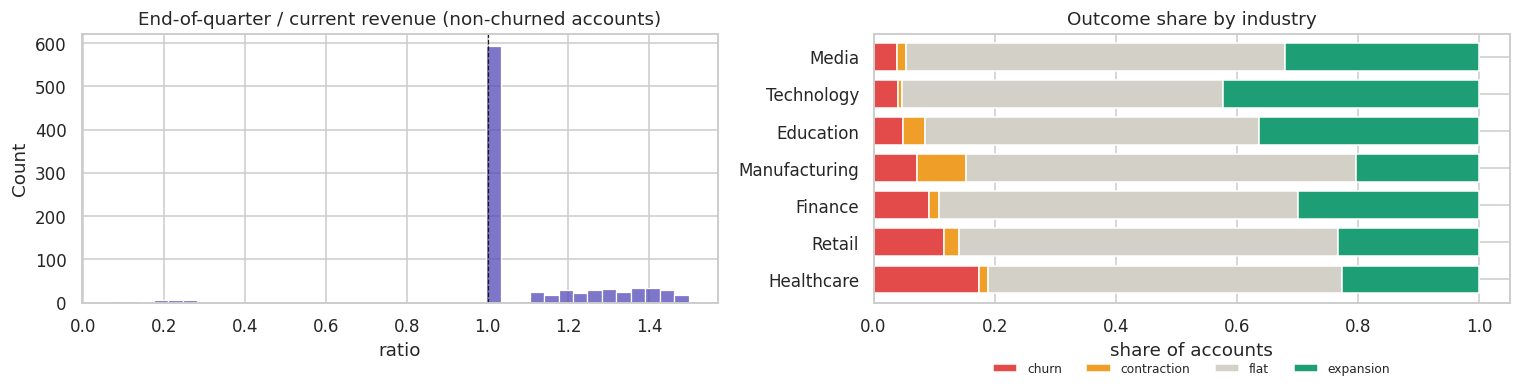

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))

moved = df[df["revenue_end_of_quarter"] > 0]
sns.histplot(moved["revenue_ratio"], bins=40, ax=axes[0], color="#534AB7")
axes[0].axvline(1, color="k", lw=0.8, ls="--")
axes[0].set_title("End-of-quarter / current revenue (non-churned accounts)")
axes[0].set_xlabel("ratio")

share = pd.crosstab(df["industry"], df["outcome"], normalize="index").loc[:, OUTCOMES]
share = share.sort_values("churn", ascending=False)
share.plot(kind="barh", stacked=True, ax=axes[1],
           color=["#E24B4A", "#EF9F27", "#D3D1C7", "#1D9E75"], width=0.75)
axes[1].set_title("Outcome share by industry")
axes[1].set_xlabel("share of accounts")
axes[1].set_ylabel("")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), fontsize=8, ncol=4, frameon=False)
plt.tight_layout()
plt.show()

In [13]:
for col in ["segment", "region"]:
    print(f"Outcome share by {col}:")
    print(pd.crosstab(df[col], df["outcome"], normalize="index").loc[:, OUTCOMES].round(3).to_string(), "\n")

Outcome share by segment:
outcome     churn  contraction   flat  expansion
segment                                         
Enterprise  0.062        0.014  0.581      0.343
Mid-Market  0.076        0.028  0.610      0.286
SMB         0.099        0.035  0.580      0.286 

Outcome share by region:
outcome  churn  contraction   flat  expansion
region                                       
APAC     0.073        0.016  0.622      0.290
EMEA     0.098        0.024  0.547      0.331
LATAM    0.073        0.033  0.623      0.272
NA       0.080        0.035  0.595      0.291 



Expansions cluster between +0% and +50% (nobody doubles). Contractions are rare but can be deep (one account kept 7% of its revenue).

Churn rate varies a lot by industry: **Healthcare 17% and Retail 12%** versus **Media 4% and Technology 4%**; Technology also expands the most (42%). Segment and region barely move the needle (churn 6–10% everywhere). Industry is therefore a plausible prior; region is not.

## 6. Which signals separate the outcomes?

First a few derived features we expect to matter:

In [14]:
df["seat_utilisation"] = df["nr_active_users"] / df["nr_licensed_seats"]
df["revenue_per_seat"] = df["current_revenue"] / df["nr_licensed_seats"]
df["has_transcript"] = df["call_transcript_summary"].notna()

signals = [
    "days_since_last_sales_activity", "nr_support_tickets", "ai_usage",
    "seat_utilisation", "days_to_next_renewal", "current_revenue",
]
df.groupby("outcome", observed=False)[signals].mean().round(3)

,days_since_last_sales_activity,nr_support_tickets,ai_usage,seat_utilisation,days_to_next_renewal,current_revenue
outcome,,,,,,
churn,98.827,6.854,0.112,0.382,132.329,183182.321
contraction,109.929,7.357,0.114,0.342,128.036,131520.491
flat,72.903,4.742,0.274,0.527,150.963,242927.268
expansion,31.388,2.091,0.510,0.729,150.708,281825.858


Already striking: churned accounts were last touched **~99 days ago** on average versus **~31 days** for expanders; they carry **three times the open tickets**, use AI features **a fifth as much**, and sit at **38% seat utilisation vs 73%**. Renewal timing barely differs (132 vs 151 days). Revenue is *not* what separates them.

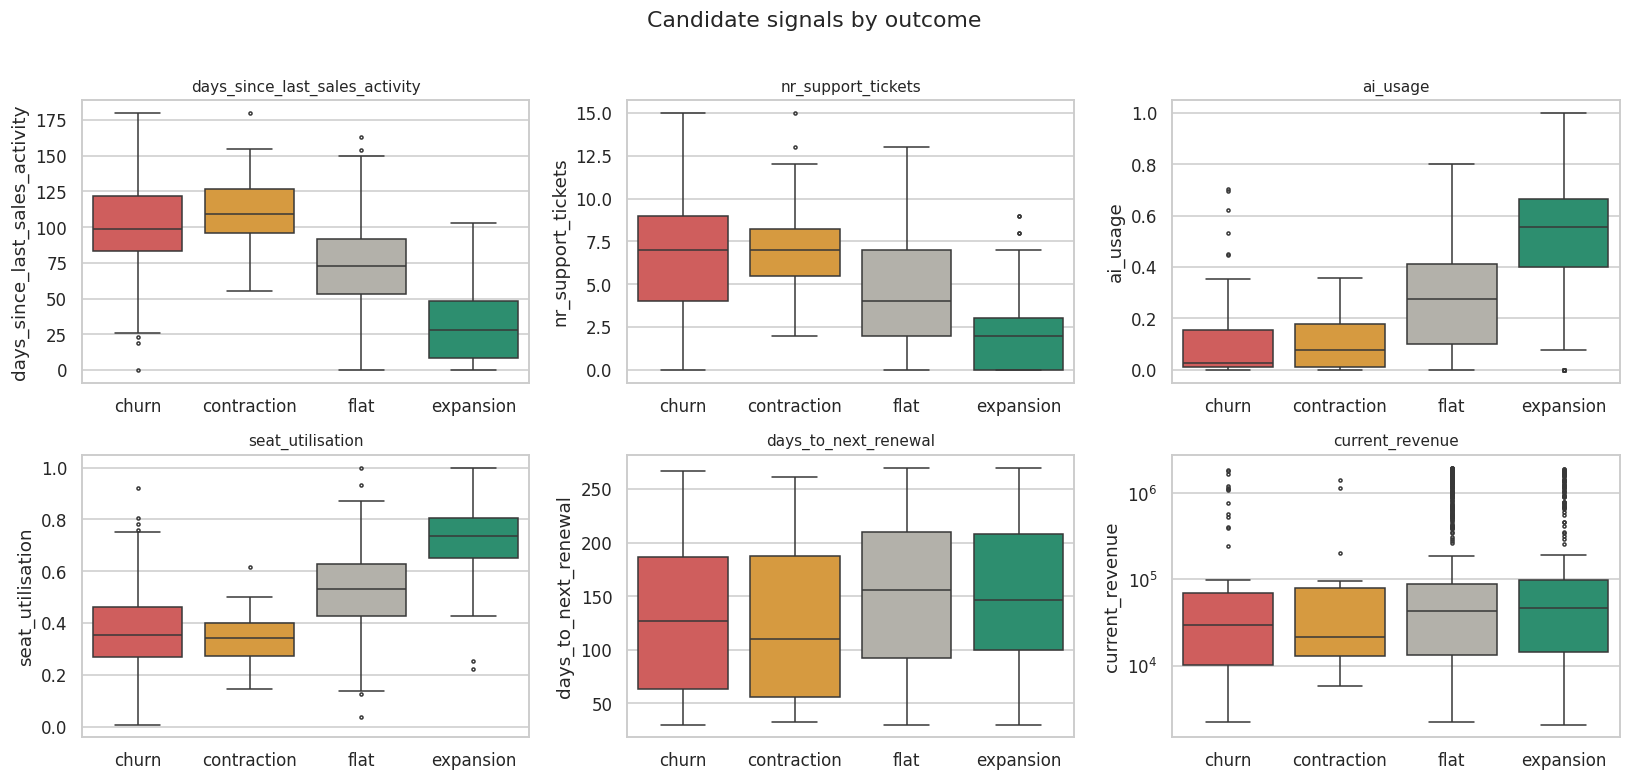

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
colors = ["#E24B4A", "#EF9F27", "#B4B2A9", "#1D9E75"]
for ax, col in zip(axes.ravel(), signals):
    sns.boxplot(data=df, x="outcome", y=col, order=OUTCOMES, ax=ax, palette=colors, fliersize=2, hue="outcome", legend=False)
    if col == "current_revenue":
        ax.set_yscale("log")
    ax.set_xlabel("")
    ax.set_title(col, fontsize=10)
fig.suptitle("Candidate signals by outcome", y=1.01)
plt.tight_layout()
plt.show()

The box plots hint at thresholds; the bucketed rates below make them explicit. For each candidate feature we bin the accounts and look at the churn rate and the expansion rate inside each bin. This is what the scoring weights and cut-offs will be based on.

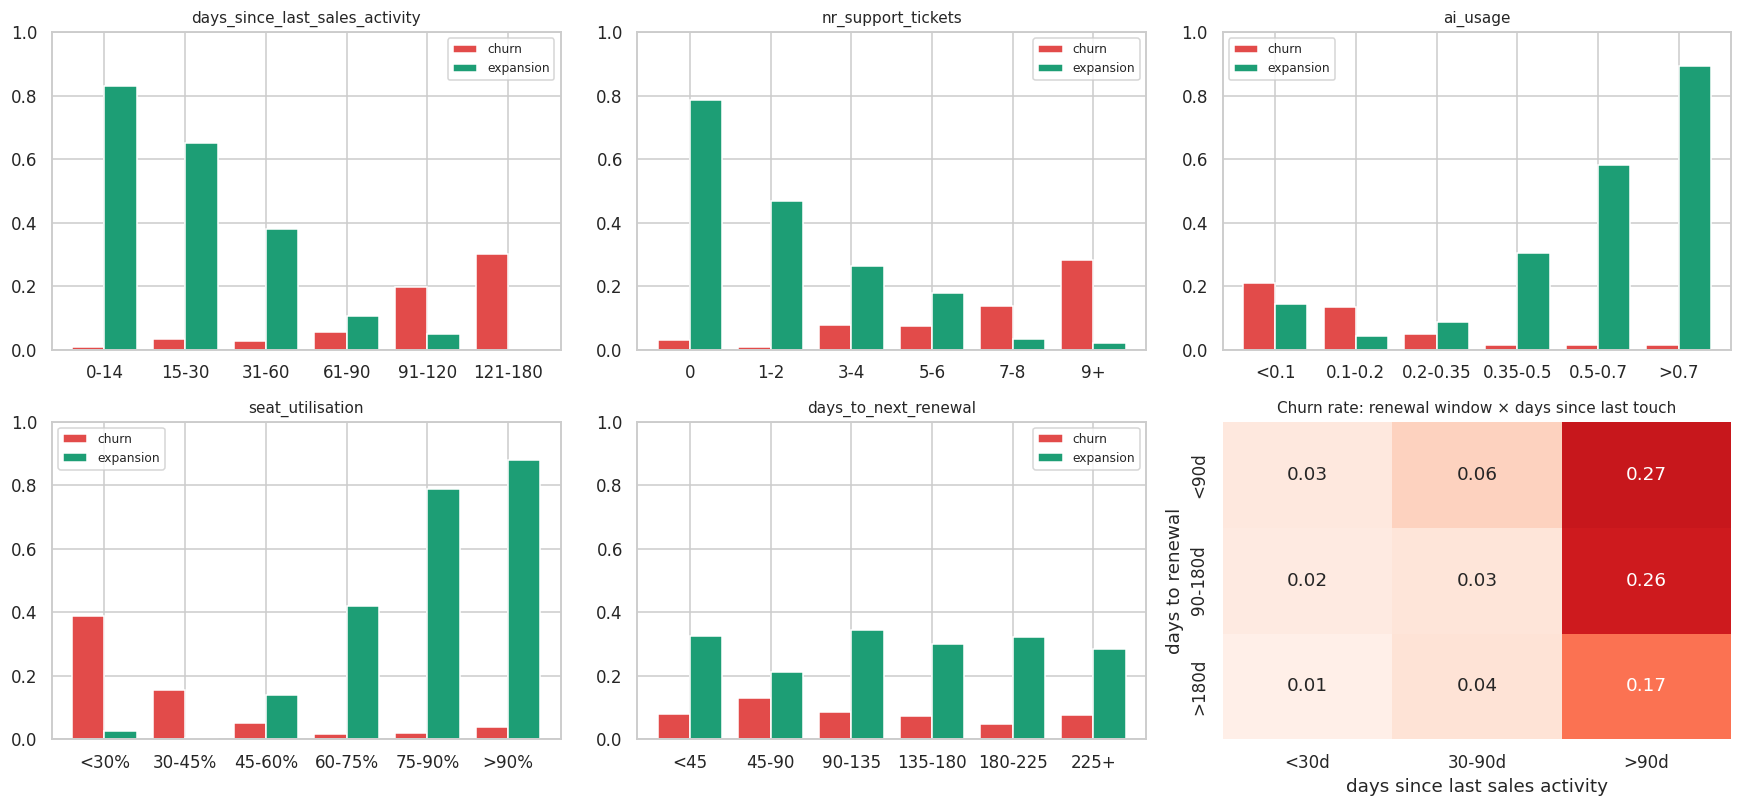

In [16]:
df["is_churn"] = (df["outcome"] == "churn").astype(int)
df["is_expansion"] = (df["outcome"] == "expansion").astype(int)

buckets = {
    "days_since_last_sales_activity": ([0, 14, 30, 60, 90, 120, 181], ["0-14", "15-30", "31-60", "61-90", "91-120", "121-180"]),
    "nr_support_tickets": ([-1, 0, 2, 4, 6, 8, 16], ["0", "1-2", "3-4", "5-6", "7-8", "9+"]),
    "ai_usage": ([-0.01, 0.1, 0.2, 0.35, 0.5, 0.7, 1.0], ["<0.1", "0.1-0.2", "0.2-0.35", "0.35-0.5", "0.5-0.7", ">0.7"]),
    "seat_utilisation": ([0, 0.3, 0.45, 0.6, 0.75, 0.9, 1.01], ["<30%", "30-45%", "45-60%", "60-75%", "75-90%", ">90%"]),
    "days_to_next_renewal": ([0, 45, 90, 135, 180, 225, 271], ["<45", "45-90", "90-135", "135-180", "180-225", "225+"]),
}

rates = {}
fig, axes = plt.subplots(2, 3, figsize=(16, 7.5))
for ax, (col, (bins, labels)) in zip(axes.ravel(), buckets.items()):
    b = pd.cut(df[col], bins=bins, labels=labels, include_lowest=True)
    t = df.groupby(b, observed=True).agg(n=("is_churn", "size"), churn=("is_churn", "mean"), expansion=("is_expansion", "mean"))
    rates[col] = t
    t[["churn", "expansion"]].plot(kind="bar", ax=ax, color=["#E24B4A", "#1D9E75"], width=0.8, rot=0)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylim(0, 1)
    ax.legend(fontsize=8)

# 6th panel: renewal window x engagement recency interaction
ren = pd.cut(df["days_to_next_renewal"], [0, 90, 180, 271], labels=["<90d", "90-180d", ">180d"])
eng = pd.cut(df["days_since_last_sales_activity"], [0, 30, 90, 181], labels=["<30d", "30-90d", ">90d"], include_lowest=True)
inter = pd.crosstab(ren, eng, values=df["is_churn"], aggfunc="mean")
sns.heatmap(inter, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=0.35, ax=axes[1, 2], cbar=False)
axes[1, 2].set_title("Churn rate: renewal window × days since last touch", fontsize=10)
axes[1, 2].set_xlabel("days since last sales activity")
axes[1, 2].set_ylabel("days to renewal")
plt.tight_layout()
plt.show()

In [17]:
for col, t in rates.items():
    print(col)
    print(t.round(3).to_string(), "\n")

days_since_last_sales_activity
                                  n  churn  expansion
days_since_last_sales_activity                       
0-14                            113  0.009      0.832
15-30                            89  0.034      0.652
31-60                           265  0.026      0.381
61-90                           279  0.057      0.108
91-120                          158  0.196      0.051
121-180                          76  0.303      0.000 

nr_support_tickets
                      n  churn  expansion
nr_support_tickets                       
0                    98  0.031      0.786
1-2                 252  0.008      0.468
3-4                 244  0.078      0.262
5-6                 186  0.075      0.177
7-8                 124  0.137      0.032
9+                   96  0.281      0.021 

ai_usage
            n  churn  expansion
ai_usage                       
<0.1      249  0.209      0.145
0.1-0.2    96  0.135      0.042
0.2-0.35  180  0.050      0.089
0.35-0.5 

Four signals are strong and **monotonic**, which is exactly what a rule-based score needs:

| signal | low-risk end | high-risk end |
|---|---|---|
| days since last sales activity | 0–14 d → **0.9% churn, 83% expansion** | 121–180 d → **30% churn, 0% expansion** |
| open support tickets | 1–2 → 0.8% churn | 9+ → 28% churn |
| AI usage | >0.7 → 1.5% churn, 89% expansion | <0.1 → 21% churn |
| seat utilisation | >75% → ~2% churn, 79–88% expansion | <30% → **39% churn** |

One expected signal is **weak on its own: days to renewal.** Churn is 8–13% in every renewal window, and the heatmap shows that an account untouched for 90+ days churns at ~25% *whether or not* renewal is close. So renewal proximity does not tell us *whether* an account is in trouble; it tells us *how soon* we have to act. In the scoring design it becomes an **urgency multiplier**, not evidence of risk.

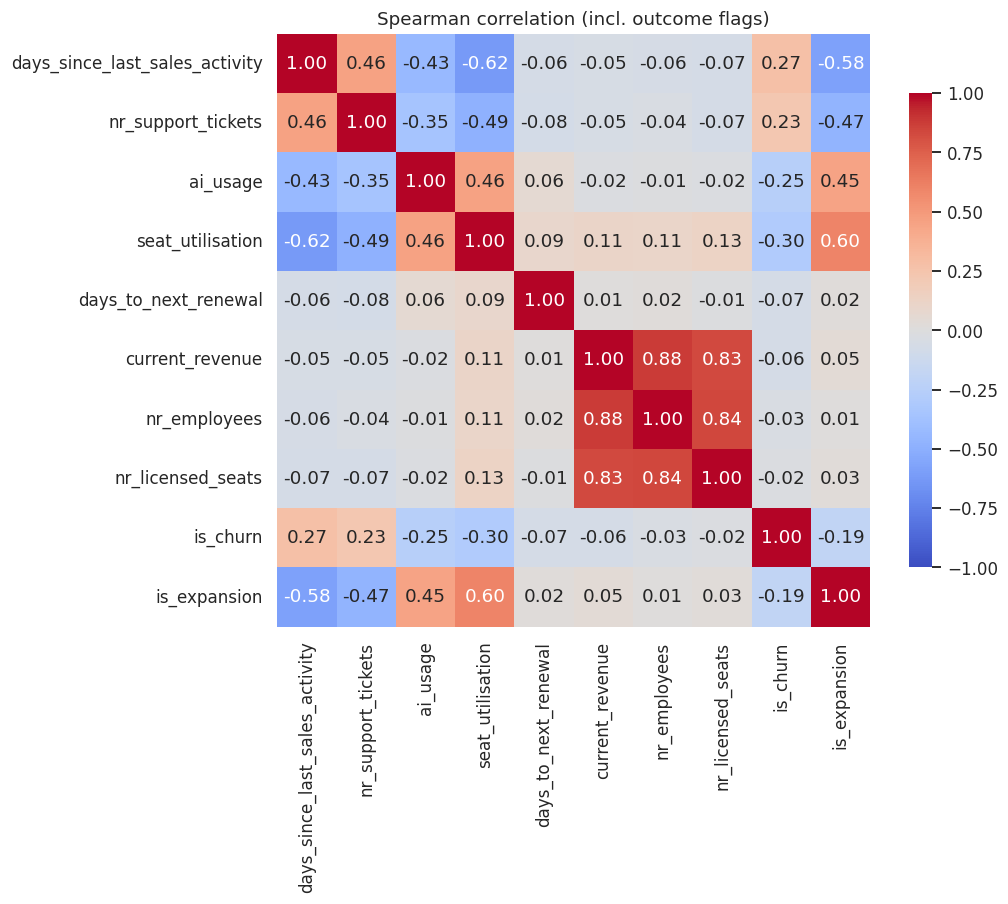

In [18]:
corr_cols = signals + ["nr_employees", "nr_licensed_seats", "is_churn", "is_expansion"]
corr = df[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax, square=True, cbar_kws={"shrink": 0.8})
ax.set_title("Spearman correlation (incl. outcome flags)")
plt.show()

The correlation matrix confirms the picture and adds one useful fact: the four strong signals are **only mildly correlated with each other** (|ρ| ≲ 0.4), so they contribute partly independent evidence and summing them is reasonable. Size and revenue have essentially zero correlation with either outcome: a revenue-sorted list would be no better than random at finding churn.

### Is missingness a signal?

In [19]:
rows = []
for col in ["call_transcript_summary", "ai_usage", "days_since_last_sales_activity"]:
    m = df[col].isna()
    rows.append({
        "column": col, "missing": int(m.sum()),
        "churn rate when missing": round(df.loc[m, "is_churn"].mean(), 3),
        "churn rate when present": round(df.loc[~m, "is_churn"].mean(), 3),
        "expansion rate when missing": round(df.loc[m, "is_expansion"].mean(), 3),
        "expansion rate when present": round(df.loc[~m, "is_expansion"].mean(), 3),
    })
pd.DataFrame(rows).set_index("column")

,missing,churn rate when missing,churn rate when present,expansion rate when missing,expansion rate when present
column,,,,,
call_transcript_summary,52,0.173,0.077,0.288,0.299
ai_usage,30,0.033,0.084,0.467,0.293
days_since_last_sales_activity,20,0.050,0.083,0.350,0.297


A **missing call transcript doubles the churn rate (17% vs 8%)**: no recent call summary most likely means no recent call. We keep it as an explicit `no_recent_call` flag rather than imputing it away. Missing `ai_usage` and missing activity dates lean, if anything, towards healthier accounts (small n = 30 and 20); we impute them with the segment median and keep a missing flag, but do not treat them as risk.

## 7. What the call transcripts say

The free-text column is the input the LLM layer will lean on most, so it is worth knowing what is in it.

In [20]:
t = df["call_transcript_summary"].dropna()
print(f"{len(t)} transcripts, {t.nunique()} distinct texts, mean length {t.str.len().mean():.0f} characters")
print("\nMost repeated summaries:")
print(t.value_counts().head(5).to_string())
print("\nExamples per outcome:")
for o in OUTCOMES:
    print(f"\n[{o}]")
    for s in df.loc[df["outcome"] == o, "call_transcript_summary"].dropna().drop_duplicates().head(3):
        print("  -", s)

948 transcripts, 447 distinct texts, mean length 96 characters

Most repeated summaries:
call_transcript_summary
Friendly call. Client appreciates the stability of the platform. No risk signals detected.                  31
Account is in maintenance mode. Head of Operations sees us as a reliable tool, not a strategic priority.    10
Brief call with COO. Budget is flat for next year. Happy but no plans to expand seats.                       9
Check-in was positive but brief. operations team has embedded the tool in their workflow.                    9
Account is using the platform as expected. customer success adoption is moderate. No new asks.               9

Examples per outcome:

[churn]
  - Budget cuts discussed. The VP of Sales indicated our tool is on the list of potential cost reductions.
  - The Head of Operations mentioned the board is pushing for a 20% software spend reduction across all departments.
  - Competitor Clari ran a demo for their finance team last week. Decision e

The summaries are short, templated and semantically loud: churners talk about *budget cuts, competitor demos, unresolved escalations, ROI concerns*; expanders about *rolling out to another team, additional seats, case studies*. A simple keyword tagger should catch most of it. Let's test that.

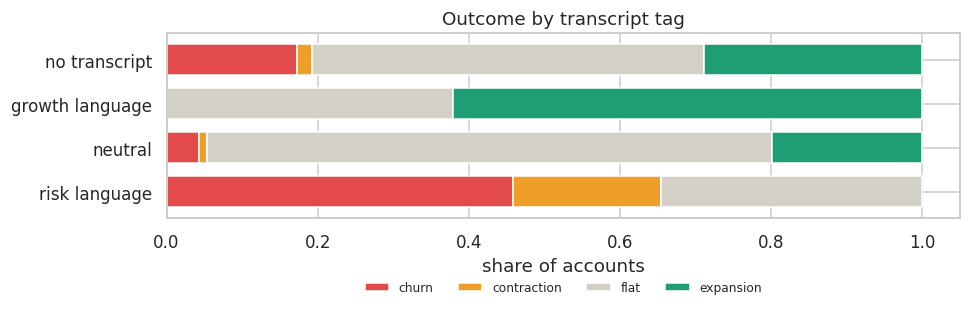

outcome,churn,contraction,flat,expansion,total
transcript_tag,,,,,
risk language,49,21,37,0,107
neutral,24,6,424,113,567
growth language,0,0,104,170,274
no transcript,9,1,27,15,52


In [21]:
RISK_TERMS = [
    "budget cut", "cost reduction", "spend reduction", "competitor", "ran a demo", "not renew",
    "may not renew", "disappoint", "cancel", "escalation", "unresolved", "in-house", "has left",
    "new leadership", "reviewing all vendor", "merging", "consolidation", "concerns about roi",
    "limited adoption", "threatened",
]
GROWTH_TERMS = [
    "expansion", "expand", "roll out", "rolling out", "additional seats", "seat add-on", "extend to",
    "case study", "more teams", "entire", "requesting",
]

def tag(text):
    if not isinstance(text, str):
        return "no transcript"
    s = text.lower()
    if any(k in s for k in RISK_TERMS):
        return "risk language"
    if any(k in s for k in GROWTH_TERMS):
        return "growth language"
    return "neutral"

df["transcript_tag"] = df["call_transcript_summary"].map(tag)
TAGS = ["risk language", "neutral", "growth language", "no transcript"]

ct = pd.crosstab(df["transcript_tag"], df["outcome"]).loc[TAGS, OUTCOMES]
share = ct.div(ct.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(9, 3.2))
share.plot(kind="barh", stacked=True, ax=ax, color=["#E24B4A", "#EF9F27", "#D3D1C7", "#1D9E75"], width=0.7)
ax.set_xlabel("share of accounts")
ax.set_ylabel("")
ax.set_title("Outcome by transcript tag")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), fontsize=8, ncol=4, frameon=False)
plt.tight_layout()
plt.show()

ct.assign(total=ct.sum(axis=1))

The tagger works well enough for a first version: **65% of accounts with risk language churned or contracted and none expanded**, while **62% of accounts with growth language expanded and none churned**. Neutral summaries sit in the middle (4% churn, 20% expansion). It is a strong feature for the score *and* gives the LLM a hook ("the last call mentioned a competitor demo"). What it cannot do is recover nuance ("satisfied, but…"), which is the LLM's job.

## 8. Implications for the scoring design

What this EDA decides for `src/data.py` and `src/scoring.py`:

**Data handling**
1. Read with `keep_default_na=False`; `NA` is North America.
2. `revenue_end_of_quarter` goes into a separate ground-truth table used only by `validate_against_ground_truth()`. It is never a feature.
3. Missing transcript → `no_recent_call = True` (it is a risk signal). Missing `ai_usage` / activity days → segment median plus a missing flag.
4. Flag the 33 accounts with seats > employees; do not use `nr_employees` as headroom for them.
5. Derived features: `seat_utilisation`, `revenue_per_seat`, `transcript_tag`, `no_recent_call`, segment-peer percentiles for the LLM context card.

**Risk score (0–100)** — evidence that the account is in trouble, from the four monotonic signals plus text:
- days since last sales activity (strongest; 0.9% → 30% churn across its range)
- seat utilisation (<30% is the single worst bucket at 39% churn)
- open support tickets
- AI usage
- risk language in the last call, or no transcript at all
- a small industry prior (Healthcare / Retail churn 2–4× Media / Technology)

**Opportunity score (0–100)** — evidence the account wants to grow: utilisation ≥75%, AI usage ≥0.5, last touch ≤30 days, 0–2 tickets, growth language in the call.

**Priority** = `max(risk, opportunity)` × **urgency** × **value**, where urgency comes from `days_to_next_renewal` (it does not change the *probability* of churn, it changes the *deadline*) and value is `log(current_revenue)` so Enterprise accounts rise but do not monopolise the list. The two scores stay visible separately so the AE knows whether they are walking into a save or a sell.

**Validation** — report what share of actually-churned accounts land in the top decile by risk, and of actually-expanded accounts in the top decile by opportunity, against a revenue-sorted baseline (which the correlation matrix says should be ~random).

## 9. Open questions to revisit

- The strength and cleanliness of the signals is partly an artefact of synthetic data. Thresholds should be presented as *starting points* an RevOps team would tune, not as truths.
- No time dimension: we cannot see trends (usage falling vs rising), which in a real CRM would be the first thing to add.
- Transcript tagging is keyword-based; a batch LLM classification pass over 948 short strings would be cheap and more robust, but is a nice-to-have within a 3–4 hour budget.